# UD3 — Sailkapen-metrikak, klase desorekatuak eta hiperparametroak (EGITEKO)

Landuko dugu:

```text
1. Confusion Matrix
2. Accuracy, Precision, Recall eta F1
3. Zein metrika, noiz?
4. Klase desorekatuak
5. class_weight eta SMOTE
6. Parametroak vs hiperparametroak
7. GridSearchCV
```

> **Balidazioaren metodologia sakona ez dugu hemen landuko.**
> Oraingoz `GridSearchCV` hiperparametro bat aukeratzeko tresna praktiko gisa erabiliko dugu.

### Nola lan egin

- 🟢 **KOMENTATU:** azaldu zure hitzekin.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU:** kode-zati labur bat idatzi.


# 0 ATALA — Prestaketa: iruzur-detekzio sintetikoa 💳

Problema:

```text
0 → transakzio normala
1 → iruzurra
```

Dataset-a nahita desorekatuta dago:

```text
≈ 95% normala
≈ 5% iruzurra
```

Horrek `accuracy`-ren arriskua oso argi ikusteko aukera emango digu.


In [1]:
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"]
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from imblearn.over_sampling import SMOTE


# ============================================================
# DATASET DESOREKATUA
# ============================================================

X, y = make_classification(
    n_samples=2000,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    weights=[0.95, 0.05],
    class_sep=1.0,
    flip_y=0.01,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN:", X_train.shape)
print("TEST :", X_test.shape)

print("\nKlase-proportzioa TRAIN-en:")
print(
    pd.Series(y_train)
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
)


TRAIN: (1600, 8)
TEST : (400, 8)

Klase-proportzioa TRAIN-en:
0    0.948
1    0.052
Name: proportion, dtype: float64


# 1 ATALA — Accuracy-ak engaina dezake ⚠️

100 kasu baditugu:

```text
95 negatibo
 5 positibo
```

eta modelo batek beti `0` esaten badu:

```text
accuracy = 95%
```

baina:

```text
recall = 0
```

Beraz:

> **Accuracy altua ez da nahikoa modelo ona dela esateko.**


In [2]:
y_egia = np.array(
    [0] * 95 +
    [1] * 5
)

# 🟡 HUTSUNEA:
# Modeloak kasu guztiak 0 direla esaten du.
y_alfer = np.zeros(
    100,
    dtype=int
)

print(
    "Accuracy:",
    accuracy_score(
        y_egia,
        y_alfer
    )
)

print(
    "Recall:",
    recall_score(
        y_egia,
        y_alfer,
        zero_division=0
    )
)


# 🟢 KOMENTATU:
#
# Nola izan daiteke accuracy = 0.95 eta recall = 0?
#
# ERANTZUNA: Accuracy-k kasu GUZTIETAN asmatutakoak neurtzen ditu. 100etik 95 negatiboak
# direnez, beti 0 esanda 95 asmatzen ditu (0.95). Baina recall-ek positiboetatik zenbat
# detektatu dituen neurtzen du: 5 positiboetatik 0 → TP = 0 → recall = 0/5 = 0.
# Modeloak ez du ezer ikasi; klase nagusia errepikatzen du. Klase desorekatuetan
# accuracy altuak ez du esan nahi modeloa ona denik.
#


Accuracy: 0.95
Recall: 0.0


# 2 ATALA — Confusion Matrix eta metrika nagusiak 📊

Binary classification batean:

| | Iragarri positiboa | Iragarri negatiboa |
|---|---:|---:|
| **Benetan positiboa** | TP | FN |
| **Benetan negatiboa** | FP | TN |

Gure iruzur-adibidean:

```text
TP → iruzurra zen eta iruzur esan dugu
TN → normala zen eta normala esan dugu
FP → normala zen baina iruzur esan dugu
FN → iruzurra zen baina normala esan dugu
```

Metrikak:

\[
Accuracy = \frac{TP+TN}{TP+TN+FP+FN}
\]

\[
Precision = \frac{TP}{TP+FP}
\]

\[
Recall = \frac{TP}{TP+FN}
\]

\[
F1 = 2\frac{Precision \cdot Recall}{Precision+Recall}
\]


TN=379  FP=0  FN=20  TP=1


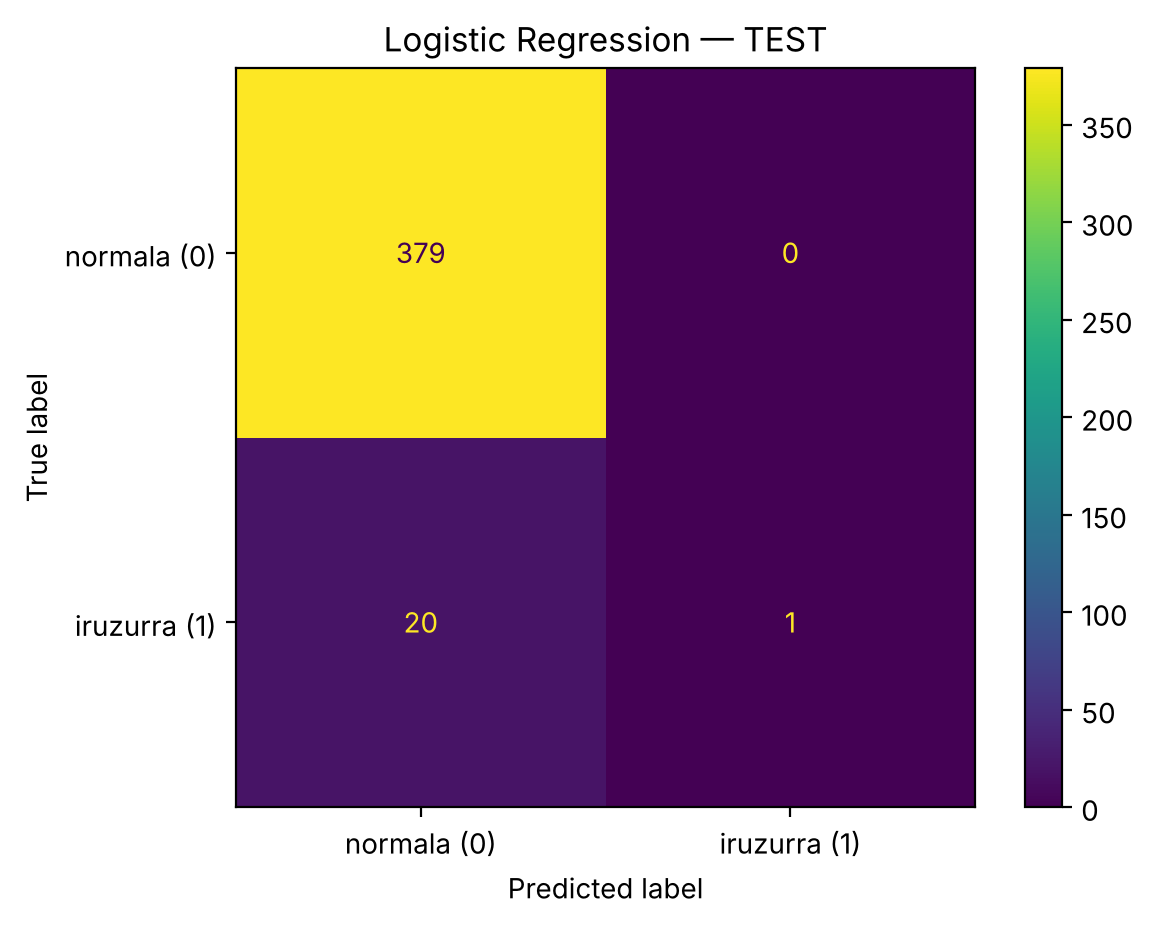

Accuracy  = 0.950
Precision = 1.000
Recall    = 0.048
F1        = 0.091


In [3]:
# ============================================================
# LOGISTIC REGRESSION BASELINE
# ============================================================

baseline = LogisticRegression(
    max_iter=2000,
    random_state=42
)

baseline.fit(
    X_train,
    y_train
)

pred = baseline.predict(
    X_test
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    pred
)

TN, FP, FN, TP = cm.ravel()

print(
    f"TN={TN}  FP={FP}  FN={FN}  TP={TP}"
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    display_labels=[
        "normala (0)",
        "iruzurra (1)"
    ]
)

plt.title(
    "Logistic Regression — TEST"
)

plt.show()


# ============================================================
# 🟡 HUTSUNEAK BETE
# ============================================================

accuracy = accuracy_score(
    y_test,
    pred
)

precision = precision_score(
    y_test,
    pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    pred,
    zero_division=0
)

print(
    f"Accuracy  = {accuracy:.3f}"
)

print(
    f"Precision = {precision:.3f}"
)

print(
    f"Recall    = {recall:.3f}"
)

print(
    f"F1        = {f1:.3f}"
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Fraud detection-en, FN batek zer esan nahi du?
#
# ERANTZUNA: Iruzurra zen transakzio bat NORMALTZAT sailkatu dela: iruzurra ez da
# detektatu eta pasatzen utzi da (dirua galtzen da). Hemen baseline-ak FN = 20 ditu
# 21 iruzurretatik: accuracy 0.95 izan arren, ia iruzur guztiak galtzen ditu
# (recall = 0.048). Fraud detection-en FN-ak dira errore garestienak.
#


In [4]:
print(
    classification_report(
        y_test,
        pred,
        target_names=[
            "normala",
            "iruzurra"
        ],
        zero_division=0
    )
)


              precision    recall  f1-score   support

     normala       0.95      1.00      0.97       379
    iruzurra       1.00      0.05      0.09        21

    accuracy                           0.95       400
   macro avg       0.97      0.52      0.53       400
weighted avg       0.95      0.95      0.93       400



# 3 ATALA — Zein metrika, noiz? 🎯

Osatu:

### Precision

Garrantzitsua da **positibo** faltsuak (FP) garestiak direnean.

Adibidea: spam sistemak email garrantzitsu bat spam gisa markatzea.

### Recall

Garrantzitsua da **negatibo** faltsuak (FN) arriskutsuak direnean.

Adibidea: iruzur bat edo gaixotasun bat ez detektatzea.

### F1

Erabilgarria da **precision** eta **recall** arteko oreka behar dugunean.

### 🟢 Hausnarketa

Fraud detection-en, zein metrika izango litzateke bereziki interesgarria?

**ERANTZUNA:** **Recall**, iruzurra ez detektatzea (FN) da errore larriena. Baseline-ak precision = 1.000 du baina recall = 0.048: ia ez du iruzurrik harrapatzen. Praktikan recall altua bilatzen da precision onargarri batekin, eta F1 erabil daiteke bien oreka ikusteko (FP gehiegik bezeroak alferrik blokeatzea ekar dezakete).


# 4 ATALA — Klase desorekatuak ⚖️

Klase bat bestea baino askoz urriagoa denean:

```text
95% / 5%
```

accuracy-ak arrakasta faltsua eman dezake.

Bi tresna ikusiko ditugu:

```text
class_weight="balanced"
SMOTE
```


In [5]:
# ============================================================
# A) CLASS_WEIGHT
# ============================================================

weighted = LogisticRegression(
    max_iter=2000,

    # 🟡 HUTSUNEA
    class_weight="balanced",

    random_state=42
)

weighted.fit(
    X_train,
    y_train
)

pred_weight = weighted.predict(
    X_test
)


# ============================================================
# B) SMOTE
# ============================================================
#
# SMOTE TRAIN-ean bakarrik aplikatu.

smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

smote_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

smote_model.fit(
    X_train_smote,
    y_train_smote
)

pred_smote = smote_model.predict(
    X_test
)


# ============================================================
# KONPARATU
# ============================================================

def metrikak(y_true, y_pred):
    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        )
    }


konparaketa = pd.DataFrame({
    "baseline": metrikak(
        y_test,
        pred
    ),
    "class_weight": metrikak(
        y_test,
        pred_weight
    ),
    "SMOTE": metrikak(
        y_test,
        pred_smote
    )
}).T

display(
    konparaketa.round(3)
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# 1. class_weight="balanced" zer egiten saiatzen da?
#
# ERANTZUNA: Klase urriaren erroreei pisu handiagoa ematen die loss-ean
# (pisua ~ n_samples / (n_klase * n_klase_horretakoak)). Iruzur bat gaizki sailkatzea
# normal bat gaizki sailkatzea baino askoz garestiagoa da entrenamenduan, beraz modeloak
# iruzurrak gehiago detektatzen ditu. Emaitza: recall 0.048 → 0.810, precision 1.0 → 0.160
# eta accuracy 0.950 → 0.768 (FP gehiago). Ez du daturik sortzen ez ezabatzen.
#
#
# 2. SMOTE-k zer sortzen du?
#
# ERANTZUNA: Klase urriko (iruzurra) adibide SINTETIKO berriak sortzen ditu: iruzur
# baten eta bere auzokide hurbilenetako baten artean (k-NN) puntu berri bat interpolatzen
# du. Horrela TRAIN-ean klaseak orekatzen dira (50/50). Emaitza class_weight-en antzekoa:
# recall 0.762, precision 0.162.
#
#
# 3. Zergatik ez dugu SMOTE TEST-ekin egiten?
#
# ERANTZUNA: TEST-ak mundu errealeko datuak irudikatu behar dituelako (~%5 iruzur).
# Datu sintetikoak sartuko bagenitu, ebaluazioa faltsua izango litzateke (asmatutako
# puntuetan neurtuko genuke) eta proportzio errealak galduko lirateke. Gainera data leakage
# izango litzateke. SMOTE entrenatzeko tresna da: TRAIN-ean bakarrik.
#


,accuracy,precision,recall,F1
baseline,0.950,1.000,0.048,0.091
class_weight,0.768,0.160,0.810,0.268
SMOTE,0.780,0.162,0.762,0.267


# 5 ATALA — Parametroak vs hiperparametroak 🔧

Osatu:

### Parametroak

Modeloak berak **ikasten** ditu entrenamenduan (datuetatik, `fit()` bitartean).

Adibidea:

```text
Logistic Regression → weights / coefficients
```

### Hiperparametroak

Guk **aukeratzen / finkatzen** ditugu entrenatu aurretik.

Adibideak:

```text
KNN → k
Decision Tree → max_depth
SVM → C
```

### 🟢 Hausnarketa

`KNeighborsClassifier(n_neighbors=5)` kodean, `5` parametroa ala hiperparametroa da?

**ERANTZUNA:** **Hiperparametroa.** `n_neighbors=5` guk aukeratzen dugu `fit()` egin aurretik; modeloak ez du datuetatik ikasten. (KNN-k, gainera, ez du parametro ikasirik: train datuak gordetzen ditu.)


# 6 ATALA — GridSearchCV: `k` aukeratzeko tresna praktikoa 🔍

Aurkezpen teorikoan bezala, `GridSearchCV` erabiliko dugu:

```text
k = 3, 5, 7, 9
```

eta tresnak konbinazioak CV-rekin probatuko ditu.

**Oraingoz ez dugu CV-ren metodologia sakon aztertuko.**

Arau bakarra:

> **TEST ez ukitu hiperparametroak aukeratzen ari garenean.**

Adibide honetan dataset sintetiko orekatu bat erabiliko dugu, eta feature-ak antzeko eskalan sortuta daude, GridSearch mekanismoan fokua mantentzeko.


In [6]:
# ============================================================
# GRIDSEARCH-ERAKO DATASET SINPLEA
# ============================================================

Xg, yg = make_classification(
    n_samples=1200,
    n_features=6,
    n_informative=5,
    n_redundant=0,
    weights=[0.5, 0.5],
    class_sep=1.2,
    random_state=7
)

Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    Xg,
    yg,
    test_size=0.20,
    random_state=42,
    stratify=yg
)


# ============================================================
# 🟡 GRIDSEARCHCV
# ============================================================

param_grid = {
    "n_neighbors": [
        3,
        5,
        7,
        9
    ]
}

bilaketa = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,

    # 🟡 HUTSUNEA
    cv=5
)

bilaketa.fit(
    Xg_train,
    yg_train
)

print(
    "k onena:",
    bilaketa.best_params_
)

print(
    "CV score onena:",
    round(
        bilaketa.best_score_,
        3
    )
)


# TEST azkenik
test_accuracy = bilaketa.best_estimator_.score(
    Xg_test,
    yg_test
)

print(
    "TEST accuracy:",
    round(
        test_accuracy,
        3
    )
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zergatik ez dugu Xg_test / yg_test erabili k aukeratzeko?
#
# ERANTZUNA: TEST-ak ikusi gabeko datuetan errendimendua neurtzeko balio duelako.
# k TEST-ekin aukeratuko bagenu, TEST-era egokitutako k bat aukeratuko genuke eta
# azken emaitza baikorregia izango litzateke (data leakage). Horregatik GridSearchCV-k
# TRAIN barruan egiten du CV-a (5 fold) eta k onena aukeratzen du (k=9, CV 0.951);
# TEST behin bakarrik erabiltzen da amaieran (0.942). CV eta TEST antzekoak direnez,
# emaitza sinesgarria da.
#


k onena: {'n_neighbors': 9}
CV score onena: 0.951
TEST accuracy: 0.942


# Amaierako laburpena ✅

Notebook honetan:

```text
Confusion Matrix
    ↓
Accuracy / Precision / Recall / F1
    ↓
zein metrika, noiz?
    ↓
klase desorekatuak
    ↓
class_weight / SMOTE
    ↓
parametroak vs hiperparametroak
    ↓
GridSearchCV
```

Oraingo mezu nagusiak:

1. **Accuracy bakarrik ez da nahikoa**, batez ere klase desorekatuetan.
2. **Precision, Recall eta F1** errore mota desberdinak ulertzeko erabiltzen dira.
3. **class_weight** eta **SMOTE** klase-desorekari aurre egiteko bi estrategia dira.
4. **Hiperparametroak** `fit()` aurretik aukeratzen ditugu.
5. **GridSearchCV** hiperparametro-balioak sistematikoki probatzeko tresna da.
6. **TEST ez dugu tuning-erako erabiltzen.**

> Balidazio-metodologia bera geroagoko unitate batean sakonduko dugu.
